In [42]:
import os
from itertools import combinations
from scipy.stats import kendalltau
import numpy as np

import torch
from botorch.fit import fit_gpytorch_model
from botorch.optim import optimize_acqf
from botorch.acquisition.preference import AnalyticExpectedUtilityOfBestOption
from botorch.models.pairwise_gp import PairwiseGP, PairwiseLaplaceMarginalLogLikelihood

In [45]:
# n = 10
# dim = 4
# n_comp = 20
# X = torch.rand(n, dim, dtype=torch.float64)
# y = utility(X)
# all_pairs = np.array(list(combinations(range(y.shape[0]), 2)))
# comp_pairs = all_pairs[np.random.choice(range(len(all_pairs)), n_comp, replace=False)]
# comp_pairs = torch.tensor(comp_pairs).long()

In [46]:
# model = PairwiseGP(X, comp_pairs)
# mll = PairwiseLaplaceMarginalLogLikelihood(model.likelihood, model)
# mll = fit_gpytorch_model(mll)

In [47]:
# Kendall-Tau rank correlation
# def eval_kt_cor(model, test_X, test_y):
#     pred_y = model.posterior(test_X).mean.squeeze().detach().numpy()
#     return kendalltau(pred_y, test_y).correlation

In [48]:
# data generating helper functions
def utility(X):
    """ Given X, output corresponding utility (i.e., the latent function)
    """
    # y is weighted sum of X, with weight sqrt(i) imposed on dimension i
    weighted_X = X * torch.sqrt(torch.arange(X.size(-1), dtype=torch.float) + 1)
    y = torch.sum(weighted_X, dim=-1)
    return y


def generate_data(n, dim=2):
    """ Generate data X and y """
    # X is randomly sampled from dim-dimentional unit cube
    # we recommend using double as opposed to float tensor here for
    # better numerical stability
    X = torch.rand(n, dim, dtype=torch.float64)
    y = utility(X)
    return X, y


def generate_comparisons(y, n_comp, noise=0.1, replace=False):
    """  Create pairwise comparisons with noise """
    # generate all possible pairs of elements in y
    all_pairs = np.array(list(combinations(range(y.shape[0]), 2)))
    # randomly select n_comp pairs from all_pairs
    comp_pairs = all_pairs[np.random.choice(range(len(all_pairs)), n_comp, replace=replace)]
    # add gaussian noise to the latent y values
    c0 = y[comp_pairs[:, 0]] + np.random.standard_normal(len(comp_pairs)) * noise
    c1 = y[comp_pairs[:, 1]] + np.random.standard_normal(len(comp_pairs)) * noise
    reverse_comp = (c0 < c1).numpy()
    comp_pairs[reverse_comp, :] = np.flip(comp_pairs[reverse_comp, :], 1)
    comp_pairs = torch.tensor(comp_pairs).long()
    return comp_pairs

def init_and_fit_model(X, comp):
    """Model fitting helper function"""
    model = PairwiseGP(X, comp)
    mll = PairwiseLaplaceMarginalLogLikelihood(model.likelihood, model)
    mll = fit_gpytorch_model(mll)
    return mll, model

def make_new_data(X, next_X, comps, q_comp):
    """Given X and next_X,
    generate q_comp new comparisons between next_X
    and return the concatenated X and comparisons
    """
    # next_X is float by default; cast it to the dtype of X (i.e., double)
    next_X = next_X.to(X)
    next_y = utility(next_X)
    next_comps = generate_comparisons(next_y, n_comp=q_comp, noise=0)
    comps = torch.cat([comps, next_comps + X.shape[-2]])
    X = torch.cat([X, next_X])
    return X, comps

In [70]:
algos = ["EUBO", "rand"]
NUM_BATCHES = 30

dim = 5
NUM_RESTARTS = 3
RAW_SAMPLES = 256
q = 2  # number of points per query
q_comp = 1  # number of comparisons per query

# initial evals
best_vals = {}  # best observed values
for algo in algos:
    best_vals[algo] = []

# average over multiple trials
torch.manual_seed(42)
np.random.seed(42)
data = {}
models = {}

# Create initial data
init_X, init_y = generate_data(q, dim=dim)
comparisons = generate_comparisons(init_y, q_comp, noise=0)
test_X, test_y = generate_data(1000, dim=dim)
# X are within the unit cube
bounds = torch.stack([torch.zeros(dim), torch.ones(dim)])

for algo in algos:
    best_vals[algo].append([])
    data[algo] = (init_X, comparisons)
    _, models[algo] = init_and_fit_model(init_X, comparisons)
    model = models[algo]

    best_next_y = utility(init_X).max().item()
    best_vals[algo][-1].append(best_next_y)

# we make additional NUM_BATCHES comparison queries after the initial observation
for j in range(1, NUM_BATCHES + 1):
    for algo in algos:
        if algo == "EUBO":
            # create the acquisition function object
            acq_func = AnalyticExpectedUtilityOfBestOption(pref_model=model)
            # optimize and get new observation
            next_X, acq_val = optimize_acqf(
                acq_function=acq_func,
                bounds=bounds,
                q=q,
                num_restarts=NUM_RESTARTS,
                raw_samples=RAW_SAMPLES,
            )
        else:
            # randomly sample data
            next_X, _ = generate_data(q, dim=dim)

        # update data
        X, comps = data[algo]
        X, comps = make_new_data(X, next_X, comps, q_comp)
        data[algo] = (X, comps)
        print(algo, X, comps)

        # refit models
        model = models[algo]
        _, model = init_and_fit_model(X, comps)
        models[algo] = model

        # record the best observed values so far
        max_val = utility(X).max().item()
        best_vals[algo][-1].append(max_val)

EUBO tensor([[0.0582, 0.0629, 0.1236, 0.0526, 0.5262],
        [0.4768, 0.9552, 0.9288, 0.0835, 0.1326],
        [1.0000, 0.0000, 1.0000, 1.0000, 1.0000],
        [0.4782, 0.9589, 0.9318, 0.0834, 0.1309]], dtype=torch.float64) tensor([[1, 0],
        [2, 3]])
rand tensor([[0.0582, 0.0629, 0.1236, 0.0526, 0.5262],
        [0.4768, 0.9552, 0.9288, 0.0835, 0.1326],
        [0.8042, 0.9676, 0.0294, 0.8140, 0.3931],
        [0.5887, 0.4280, 0.2808, 0.7571, 0.9868]], dtype=torch.float64) tensor([[1, 0],
        [3, 2]])
EUBO tensor([[0.0582, 0.0629, 0.1236, 0.0526, 0.5262],
        [0.4768, 0.9552, 0.9288, 0.0835, 0.1326],
        [1.0000, 0.0000, 1.0000, 1.0000, 1.0000],
        [0.4782, 0.9589, 0.9318, 0.0834, 0.1309],
        [0.4749, 0.9590, 0.9416, 0.0756, 0.1280],
        [0.5893, 0.3906, 0.3104, 0.7800, 1.0000]], dtype=torch.float64) tensor([[1, 0],
        [2, 3],
        [5, 4]])


/Users/changkun/miniconda3/envs/bo/lib/python3.9/site-packages/botorch/fit.py:155: RuntimeWarning: Fitting failed on all retries.
  warnings.warn("Fitting failed on all retries.", RuntimeWarning)


rand tensor([[0.0582, 0.0629, 0.1236, 0.0526, 0.5262],
        [0.4768, 0.9552, 0.9288, 0.0835, 0.1326],
        [0.8042, 0.9676, 0.0294, 0.8140, 0.3931],
        [0.5887, 0.4280, 0.2808, 0.7571, 0.9868],
        [0.9426, 0.8316, 0.5363, 0.0209, 0.7356],
        [0.5130, 0.0320, 0.3116, 0.6831, 0.7889]], dtype=torch.float64) tensor([[1, 0],
        [3, 2],
        [4, 5]])
EUBO tensor([[0.0582, 0.0629, 0.1236, 0.0526, 0.5262],
        [0.4768, 0.9552, 0.9288, 0.0835, 0.1326],
        [1.0000, 0.0000, 1.0000, 1.0000, 1.0000],
        [0.4782, 0.9589, 0.9318, 0.0834, 0.1309],
        [0.4749, 0.9590, 0.9416, 0.0756, 0.1280],
        [0.5893, 0.3906, 0.3104, 0.7800, 1.0000],
        [0.6822, 0.5402, 0.3353, 0.6657, 1.0000],
        [0.6775, 0.9094, 0.8030, 0.0000, 0.3790]], dtype=torch.float64) tensor([[1, 0],
        [2, 3],
        [5, 4],
        [6, 7]])
rand tensor([[0.0582, 0.0629, 0.1236, 0.0526, 0.5262],
        [0.4768, 0.9552, 0.9288, 0.0835, 0.1326],
        [0.8042, 0.9676, 0.

/Users/changkun/miniconda3/envs/bo/lib/python3.9/site-packages/botorch/fit.py:148: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(w.message, w.category)


rand tensor([[5.8154e-02, 6.2910e-02, 1.2359e-01, 5.2580e-02, 5.2617e-01],
        [4.7678e-01, 9.5524e-01, 9.2875e-01, 8.3543e-02, 1.3264e-01],
        [8.0415e-01, 9.6758e-01, 2.9374e-02, 8.1403e-01, 3.9314e-01],
        [5.8874e-01, 4.2796e-01, 2.8078e-01, 7.5710e-01, 9.8683e-01],
        [9.4264e-01, 8.3159e-01, 5.3630e-01, 2.0902e-02, 7.3558e-01],
        [5.1299e-01, 3.2003e-02, 3.1160e-01, 6.8312e-01, 7.8890e-01],
        [5.5770e-02, 1.1325e-01, 1.9639e-01, 2.1529e-01, 3.1878e-01],
        [8.8098e-01, 8.3654e-01, 7.3866e-01, 1.9290e-01, 8.8795e-01],
        [7.9899e-01, 1.1223e-01, 2.7147e-01, 3.2786e-01, 9.3817e-01],
        [1.2387e-02, 2.0577e-01, 2.1456e-01, 2.0475e-01, 9.4022e-01],
        [3.6879e-01, 2.8951e-01, 9.0823e-01, 1.6270e-01, 6.8841e-01],
        [4.7329e-01, 1.9548e-01, 9.5032e-01, 8.2970e-01, 2.3482e-01],
        [9.8101e-01, 5.6336e-01, 4.4283e-01, 3.3537e-01, 8.2368e-01],
        [1.3491e-01, 3.1999e-01, 6.5485e-01, 6.3524e-05, 8.5427e-01],
        [9.6667

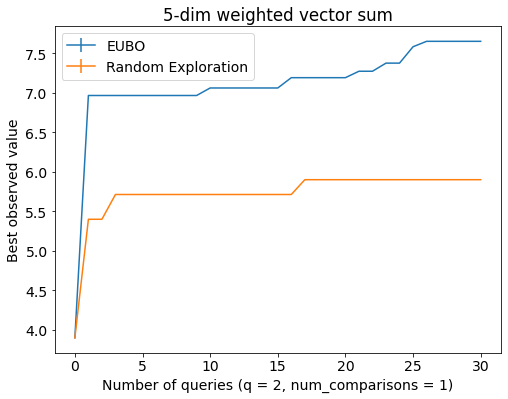

In [57]:
from matplotlib import pyplot as plt
plt.rcParams.update({"font.size": 14})
algo_labels = {
    'rand': 'Random Exploration',
    'EUBO': 'EUBO',
}
def ci(y):
    return 1.96 * y.std(axis=0) / np.sqrt(y.shape[0])

iters = list(range(NUM_BATCHES + 1))
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

# plot the the best observed value from each algorithm
for algo in algos:
    ys = np.vstack(best_vals[algo])
    ax.errorbar(iters, ys.mean(axis=0), yerr=ci(ys), label=algo_labels[algo], linewidth=1.5)

ax.set(
    xlabel=f"Number of queries (q = {q}, num_comparisons = {q_comp})",
    ylabel="Best observed value",
    title=f"{dim}-dim weighted vector sum",
)
ax.legend(loc="best")

In [79]:
# average over multiple trials
torch.manual_seed(42)
np.random.seed(42)

q_comp = 1  # number of comparisons per query
dim = 5
n = 4
X = torch.rand(2, dim, dtype=torch.float64)
all_pairs = np.array(list(combinations(range(utility(X).shape[0]), 2)))
comparisons = torch.tensor(all_pairs[np.random.choice(range(len(all_pairs)), q_comp, replace=False)]).long()
print('X: ', X)
print('comparisons: ', comparisons)

model = PairwiseGP(X, comparisons)
mll = PairwiseLaplaceMarginalLogLikelihood(model.likelihood, model)
mll = fit_gpytorch_model(mll)
next_X, acq_val = optimize_acqf(
    acq_function=AnalyticExpectedUtilityOfBestOption(pref_model=model),
    bounds=torch.stack([torch.zeros(dim), torch.ones(dim)]),
    q=2,
    num_restarts=NUM_RESTARTS,
    raw_samples=RAW_SAMPLES,
)

print(next_X, acq_val)

X:  tensor([[0.0582, 0.0629, 0.1236, 0.0526, 0.5262],
        [0.4768, 0.9552, 0.9288, 0.0835, 0.1326]], dtype=torch.float64)
comparisons:  tensor([[0, 1]])
tensor([[0.1040, 0.0968, 0.2231, 0.0677, 0.8732],
        [0.0091, 0.0223, 0.0180, 0.0372, 0.1823]]) tensor(0.7434, dtype=torch.float64)
